
# Predicting Employee Turnover Using Machine Learning

**Python | Decision Tree Classification | People Analytics | Workforce Retention**

## Project Overview

Employee turnover can create recruitment costs, disrupt operations and affect organizational performance.

This project applies Decision Tree classification to historical employee data to identify patterns associated with turnover and examine how predictive analytics could support workforce planning.

The analysis includes data preparation, classification modeling, model evaluation, feature importance and business recommendations.

## Business Objectives

- Analyze employee turnover patterns.
- Develop a Decision Tree classification model.
- Evaluate the model using precision, recall, F1-score and accuracy.
- Identify employee characteristics associated with turnover.
- Translate predictive findings into potential retention strategies.


# **Importing Necessary Libraries and Data**

In [122]:
# Importing pandas (as pd) to read the data
import pandas as pd
from sklearn.model_selection import train_test_split

In [123]:
import requests
from io import StringIO
orig_url="https://drive.google.com/file/d/1rITOxfR2PXnroEPQqc4TMtv-7sFPLK7d/view?usp=drive_link" # share link to data set

file_id = orig_url.split('/')[-2]
dwn_url='https://drive.google.com/uc?export=download&id=' + file_id
url = requests.get(dwn_url).text

csv_raw = StringIO(url)
data= pd.read_csv(csv_raw)


# Data Handling

In [124]:
# Taking a quick look to the first 5 rows of data
print(data.head())

# Getting some information on the types of variables in data
data.info()

   satisfaction  evaluation  number_of_projects  average_montly_hours  \
0          0.38        0.53                   2                   157   
1          0.80        0.86                   5                   262   
2          0.11        0.88                   7                   272   
3          0.72        0.87                   5                   223   
4          0.37        0.52                   2                   159   

   time_spend_company  work_accident  churn  promotion department  salary  
0                   3              0      1          0      sales     low  
1                   6              0      1          0      sales  medium  
2                   4              0      1          0      sales  medium  
3                   5              0      1          0      sales     low  
4                   3              0      1          0      sales     low  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 column

In [125]:
# Printing the unique values of the "department" column
print(data.department.unique())

# Printing the unique values of the "salary" column
print(data.salary.unique())

['sales' 'accounting' 'hr' 'technical' 'support' 'management' 'IT'
 'product_mng' 'marketing' 'RandD']
['low' 'medium' 'high']


In [126]:
# Changing the type of the "salary" column to categorical
data.salary = data.salary.astype('category')

In [127]:
# Providing the correct order of categories
data.salary = data.salary.cat.reorder_categories(['low', 'medium', 'high'])

In [128]:
# Encoding categories
data.salary = data.salary.cat.codes

# **Converting Department into Nominal Variable**


In [129]:
# Getting dummies and saving them inside a new DataFrame
departments = pd.get_dummies(data.department)

# Taking a quick look to the first 5 rows of the new DataFrame called departments
print(departments.head())

      IT  RandD  accounting     hr  management  marketing  product_mng  sales  \
0  False  False       False  False       False      False        False   True   
1  False  False       False  False       False      False        False   True   
2  False  False       False  False       False      False        False   True   
3  False  False       False  False       False      False        False   True   
4  False  False       False  False       False      False        False   True   

   support  technical  
0    False      False  
1    False      False  
2    False      False  
3    False      False  
4    False      False  



# Dummy Trap
A dummy trap is a situation where different dummy variables convey the same information. In this case, if an employee is, say, from the accounting department (i.e. value in the accounting column is 1), then we're certain that s/he is not from any other department (values everywhere else are 0). Thus, we could actually learn about his/her department by looking at all the other departments.

For that reason, whenever n dummies are created (in our case, 10), only 1 (in our case, 9) of them are enough, and the mth column's information is already included.

Therefore, we get rid of the old department column, drop one of the department dummies to avoid dummy trap, and then join the two DataFrames.

In [130]:
# Dropping the "accounting" column to avoid "dummy trap"
departments = departments.drop("accounting", axis=1)

# Dropping the old column "department" as we don't need it anymore
data = data.drop("department", axis=1)

# Joining the new DataFrame "departments" to the employee dataset
data = data.join(departments)

## Data Cleaning and Feature Preparation

In [131]:

# Remove exact duplicate records before modeling
data_clean = data.drop_duplicates().copy()

print("Original records:", len(data))
print("Records after cleaning:", len(data_clean))
print("Duplicates removed:", len(data) - len(data_clean))

# Prepare features and target
features = data_clean.drop(columns=["churn"])
target = data_clean["churn"]


Original records: 14999
Records after cleaning: 11991
Duplicates removed: 3008



## Employee Turnover Rate

The `churn` variable indicates employee turnover:
- **0:** Employee stayed
- **1:** Employee left

After removing 3,008 identical records, the cleaned dataset contains 11,991 employee records.

- **Employees who stayed:** 10,000
- **Employees who left:** 1,991
- **Overall turnover rate:** 16.60%

The dataset has an unequal distribution of employees who stayed and employees who left. Therefore, precision, recall and F1-score are important when evaluating the classification model.

**Note:** Identical records were removed as a modeling assumption because unique employee identifiers were unavailable.


In [132]:

# Employee turnover distribution after cleaning
turnover_counts = data_clean["churn"].value_counts()
turnover_percentages = (
    data_clean["churn"].value_counts(normalize=True) * 100
)

print("Turnover counts:")
print(turnover_counts)

print("\nTurnover percentages:")
print(turnover_percentages.round(2))


Turnover counts:
churn
0    10000
1     1991
Name: count, dtype: int64

Turnover percentages:
churn
0    83.4
1    16.6
Name: proportion, dtype: float64


# **Splitting the Data**


In [133]:

# Split features and target into training and testing sets
features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.25,
    random_state=42,
    stratify=target
)

print("Training records:", features_train.shape[0])
print("Testing records:", features_test.shape[0])

print(
    "Training turnover rate:",
    round(target_train.mean() * 100, 2), "%"
)

print(
    "Testing turnover rate:",
    round(target_test.mean() * 100, 2), "%"
)


Training records: 8993
Testing records: 2998
Training turnover rate: 16.6 %
Testing turnover rate: 16.61 %


# **Computing Gini index**

The decision tree algorithm aims to achieve partitions in the terminal nodes that are as pure as possible. The Gini index is one of the methods used to achieve this. It is calculated based on the proportion of samples in each group.

In [134]:
#number of people who stayed/left
stayed = 37
left = 1138

#sum of stayed and left
total = stayed+ left

#gini index
gini = 2*(stayed/total)*(left/total)


**Note:** The Gini calculation above is an illustrative example of node impurity. The counts used in this example are not the overall employee turnover distribution in the cleaned dataset.


## Decision Tree Model Training

A Decision Tree classifier is trained using Gini impurity with a maximum depth of five and a minimum of 20 samples per leaf to limit model complexity.

In [135]:

from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree classifier
decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

# Train the model
decision_tree.fit(features_train, target_train)

# Generate predictions
train_predictions = decision_tree.predict(features_train)
test_predictions = decision_tree.predict(features_test)

print("Decision Tree model trained successfully!")
print("Training predictions:", len(train_predictions))
print("Testing predictions:", len(test_predictions))


Decision Tree model trained successfully!
Training predictions: 8993
Testing predictions: 2998



## Decision Tree Model Evaluation

The model is evaluated using accuracy, precision, recall and F1-score on both training and testing data.

Particular attention is given to recall for employees who leave (Class 1) because failing to identify potential turnover cases could limit opportunities for proactive retention strategies.

Comparing training and testing performance also helps identify potential overfitting.


In [136]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Evaluate training and testing performance
for name, actual, predicted in [
    ("Training", target_train, train_predictions),
    ("Testing", target_test, test_predictions)
]:
    print(f"\n{name} Performance")
    print("-" * 35)

    print("Accuracy:",
          round(accuracy_score(actual, predicted), 4))

    print("Precision:",
          round(precision_score(actual, predicted, zero_division=0), 4))

    print("Recall:",
          round(recall_score(actual, predicted, zero_division=0), 4))

    print("F1-score:",
          round(f1_score(actual, predicted, zero_division=0), 4))

print("\nDetailed Test Classification Report")
print(classification_report(
    target_test,
    test_predictions,
    target_names=["Stayed", "Left"],
    zero_division=0
))



Training Performance
-----------------------------------
Accuracy: 0.9772
Precision: 0.9607
Recall: 0.8995
F1-score: 0.9291

Testing Performance
-----------------------------------
Accuracy: 0.9793
Precision: 0.9619
Recall: 0.9116
F1-score: 0.9361

Detailed Test Classification Report
              precision    recall  f1-score   support

      Stayed       0.98      0.99      0.99      2500
        Left       0.96      0.91      0.94       498

    accuracy                           0.98      2998
   macro avg       0.97      0.95      0.96      2998
weighted avg       0.98      0.98      0.98      2998




## Confusion Matrix Analysis

The confusion matrix illustrates the model's predictions across four categories:

- **True Negatives:** Employees correctly predicted to stay.
- **True Positives:** Employees correctly predicted to leave.
- **False Positives:** Employees predicted to leave who actually stayed.
- **False Negatives:** Employees who left but were predicted to stay.

In employee turnover prediction, false negatives are particularly important because they represent potential retention risks the model failed to identify.


<Figure size 700x500 with 0 Axes>

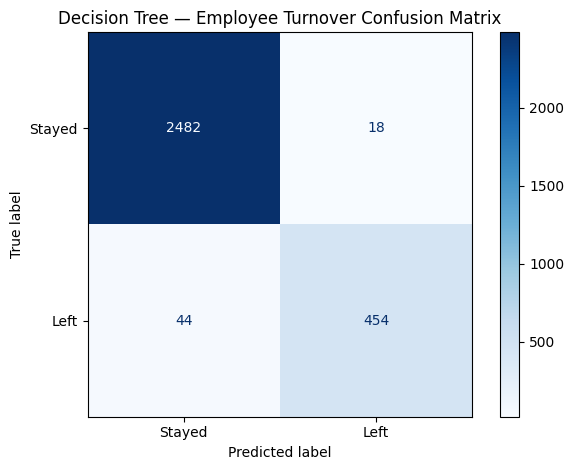

In [137]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    target_test,
    test_predictions,
    display_labels=["Stayed", "Left"],
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree — Employee Turnover Confusion Matrix")
plt.tight_layout()
plt.show()



## Feature Importance Analysis

Feature importance helps identify which employee characteristics contribute most to the Decision Tree's predictions.

This analysis can highlight factors associated with employee turnover and support further investigation into potential retention risks.


,Feature,Importance
0,satisfaction,0.522314
1,evaluation,0.175318
4,time_spend_company,0.124188
2,number_of_projects,0.118821
3,average_montly_hours,0.058954
7,salary,0.000406
5,work_accident,0.000000
6,promotion,0.000000
8,IT,0.000000
9,RandD,0.000000


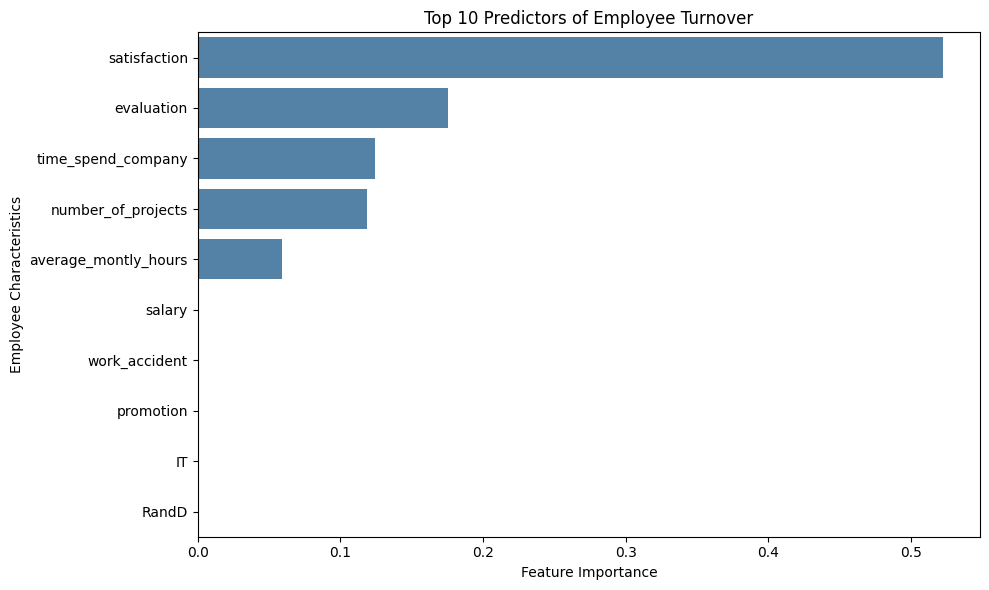

In [138]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": features_train.columns,
    "Importance": decision_tree.feature_importances_
}).sort_values("Importance", ascending=False)

# Display top 10 features
display(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Predictors of Employee Turnover")
plt.xlabel("Feature Importance")
plt.ylabel("Employee Characteristics")
plt.tight_layout()
plt.show()



### Feature Importance: Key Observations

The Decision Tree identified five primary predictors of employee turnover:

- **Employee satisfaction:** 52.23%
- **Performance evaluation:** 17.53%
- **Tenure:** 12.42%
- **Number of projects:** 11.88%
- **Average monthly working hours:** 5.90%

Employee satisfaction contributed the most to the model's predictions. Performance evaluations, tenure and workload-related variables provided additional predictive information.

Other features including salary, department and promotions had little or no importance in this particular model.

These findings identify predictive relationships rather than causal drivers of employee turnover.


In [139]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    decision_tree,
    features_train,
    target_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    }
)

for metric in ["accuracy", "precision", "recall", "f1"]:
    values = scores[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{values.mean():.4f} (+/- {values.std():.4f})"
    )


Accuracy: 0.9754 (+/- 0.0033)
Precision: 0.9436 (+/- 0.0087)
Recall: 0.9062 (+/- 0.0203)
F1: 0.9244 (+/- 0.0107)



### Cross-Validation Results

Five-fold stratified cross-validation on the cleaned training dataset produced:

- **Accuracy:** 97.54%
- **Precision:** 94.36%
- **Recall:** 90.62%
- **F1-score:** 92.44%

The relatively small variation across folds suggests stable model performance.

These findings are consistent with the held-out test results and support the model's predictive reliability within this dataset.


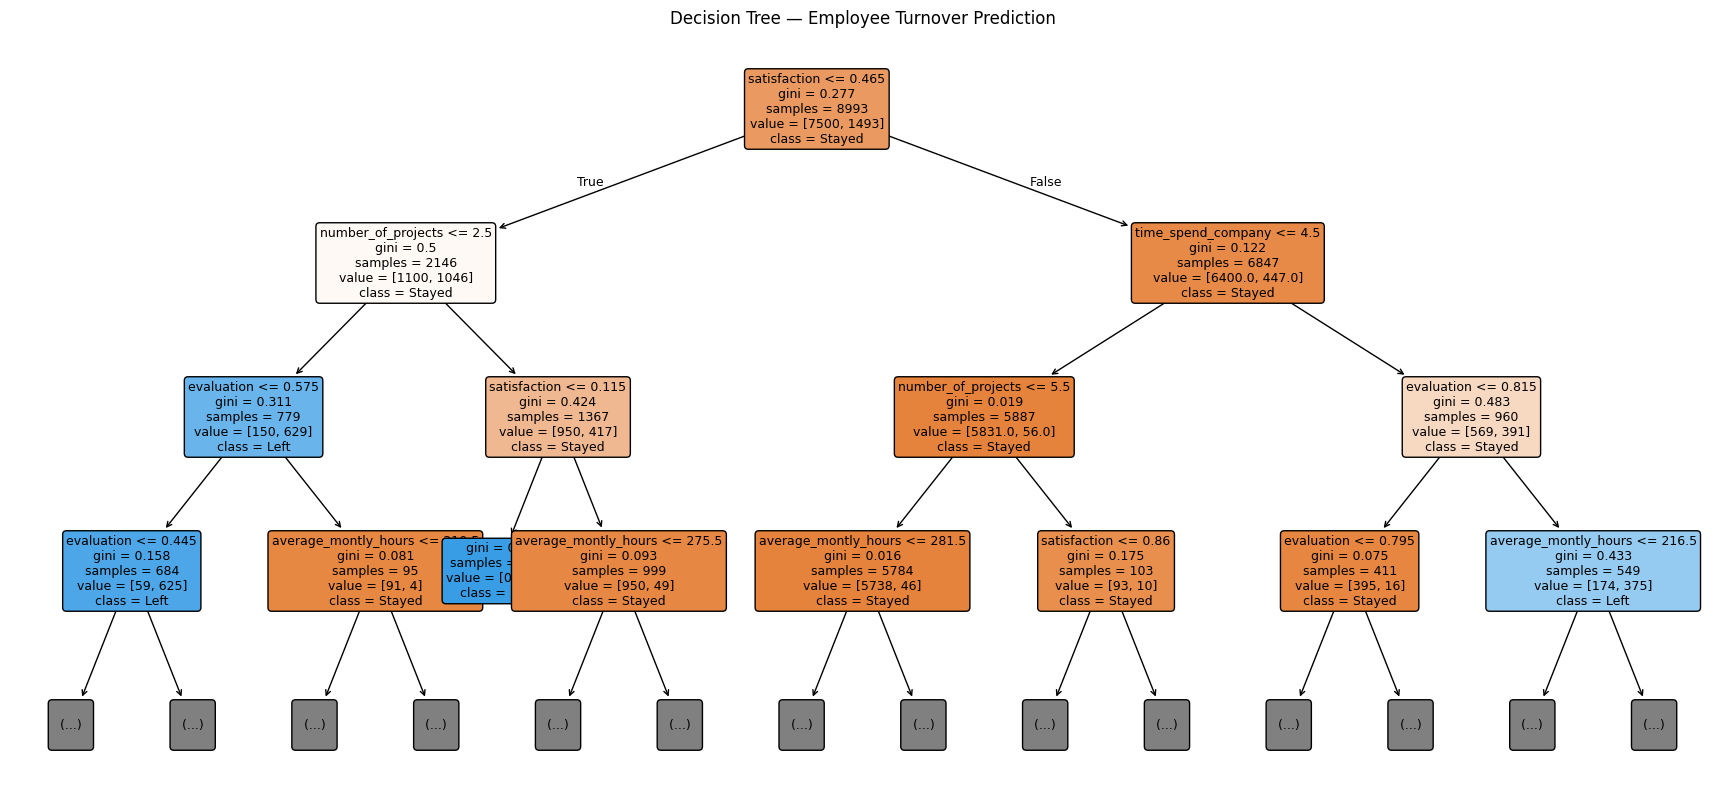

In [140]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    decision_tree,
    feature_names=features_train.columns,
    class_names=["Stayed", "Left"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree — Employee Turnover Prediction")
plt.show()



### Decision Tree: Key Observations

- **Employee satisfaction** is the first splitting variable in the Decision Tree, with a threshold of 0.465. Employees with satisfaction scores below this threshold show a higher concentration of turnover cases.

- **Number of projects** helps distinguish turnover patterns among employees with lower satisfaction levels. Employees with different workloads exhibit varying turnover risks.

- **Performance evaluations** provide additional predictive information, particularly when combined with satisfaction levels and project workload.

- **Employee tenure** is another important factor. The model uses a tenure threshold of 4.5 years to further differentiate employee groups with varying turnover patterns.

- **Average monthly working hours** contribute to subsequent decisions in the tree, suggesting that workload-related characteristics may help identify employees at greater risk of leaving.

### Business Interpretation

The Decision Tree suggests that employee turnover is associated with a combination of satisfaction, performance, tenure and workload characteristics rather than a single factor.

These findings highlight potential areas for HR teams to investigate when developing employee retention strategies.

**Note:** The relationships identified by the model are predictive rather than causal. The results do not establish that changing any individual factor would directly reduce employee turnover.



# Overall Findings and Business Recommendations

## Key Findings

The Decision Tree achieved 97.93% test accuracy and correctly identified 91.16% of employees who left after removing exact duplicate records.

Employee satisfaction emerged as the strongest predictor, followed by performance evaluations, tenure, number of projects and average monthly working hours.

The results suggest that employee experience and workload-related characteristics are particularly useful for identifying potential turnover patterns.

## Business Recommendations

### 1. Monitor Employee Satisfaction

Introduce regular satisfaction assessments to identify employees who may require additional support.

### 2. Review Workload Distribution

Investigate employee groups with unusually high project loads or working hours and evaluate opportunities to improve workload balance.

### 3. Examine Tenure-Related Patterns

Analyze retention patterns across employee tenure groups to identify periods associated with elevated turnover risk.

### 4. Improve Performance Conversations

Use performance evaluations alongside employee feedback to identify opportunities for career development and improved manager support.

### 5. Validate Before Operational Use

Evaluate the model using newer employee records before considering real-world applications.

Any retention initiatives should be evaluated for effectiveness and should not rely solely on automated predictions about individual employees.

## Limitations and Future Scope

- The dataset does not contain unique employee identifiers. Exact duplicate records were removed for modeling but may represent different employees with identical characteristics.
- The analysis uses historical data and does not establish causal relationships.
- Employee satisfaction, performance evaluations and workload information must be available before the prediction date for real-world use.
- Additional validation is needed to assess model stability across different employee populations and time periods.
- Future analysis could examine model calibration, potential bias across employee groups and the effectiveness of voluntary retention initiatives.

## Conclusion

The analysis demonstrates how Decision Tree classification can identify patterns associated with employee turnover.

Combining predictive modeling with responsible workforce analysis could help HR teams investigate retention challenges and design better-informed employee support strategies.
